# 🎬 Movie Market Analysis

**Company:** CineData Studios
**Role:** Media Strategy Analyst

## 🎥 Scenario

CineData Studios is planning their next big production. The executive team wants to analyze historical movie data to determine which genres are currently **most profitable** and **highly rated**, helping guide strategic investment decisions.

---

## 🎯 Your Tasks

### 1️⃣ Rating Score Analysis

* Calculate the **average IMDB rating** across all movies in the dataset.
* This represents the overall quality benchmark.

---

### 2️⃣ Genre King 👑

* Group movies by **Genre**.
* Compute the **average rating per genre**.
* Identify which genre has the **highest average rating**.

---

### 3️⃣ Financial Impact Analysis

* Create a **Bar Chart** showing:

```
Genre vs. Box Office Revenue
```

* This will help identify the most financially successful genres.
* Include:

  * Chart title
  * Axis labels
  * Clear formatting

---

### 4️⃣ Rating Distribution

* Create a **Histogram** of movie ratings.

* Include:

  * Title
  * Axis labels
  * Grid (optional)

* Analyze how ratings are distributed across films.

---

### 5️⃣ Success Metric – Hit Identification

* Create a new column called **`Hit`** where:

```
Hit = True  if Rating ≥ 8  
Hit = False if Rating < 8
```

* This helps classify critically successful movies.

---

### 6️⃣ Hit Movie Tally

* Count the total number of **“Hit”** movies in the dataset.
* Optionally calculate the percentage of hits.

---

## 📌 Expected Outcome

By completing this analysis, you should be able to:

* Understand overall movie rating trends
* Identify the highest-rated genres
* Analyze revenue performance by genre
* Recognize critically successful films
* Provide data-driven recommendations for future productions

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Load the dataset
df = pd.read_csv("/content/movie_ratings_dataset.csv")

# Calculate the overall average IMDb rating
average_imdb_rating = df["IMDB_Rating"].mean()

# Display result
print(f"Average IMDb Rating Across All Movies: {average_imdb_rating:.2f} / 10")

Average IMDb Rating Across All Movies: 7.21 / 10


In [4]:
# Calculate the average IMDb rating for each genre
genre_avg_ratings = (
    df.groupby("Genre")["IMDB_Rating"]
      .mean()
      .sort_values(ascending=False)
)

# Display average ratings by genre
print("Average IMDb Rating by Genre:")
print(genre_avg_ratings.round(2))

# Identify the genre with the highest average rating
top_genre = genre_avg_ratings.idxmax()
top_genre_rating = genre_avg_ratings.max()

print(f"\nGenre King: {top_genre}")
print(f"Highest Average IMDb Rating: {top_genre_rating:.2f} / 10")


Average IMDb Rating by Genre:
Genre
Thriller    7.53
Action      7.50
Comedy      7.23
Drama       6.46
Name: IMDB_Rating, dtype: float64

Genre King: Thriller
Highest Average IMDb Rating: 7.53 / 10


Total Box Office Revenue by Genre (Millions):
      Genre  Box_Office_Millions
3  Thriller               1777.2
0    Action               1383.8
2     Drama               1339.9
1    Comedy               1076.1


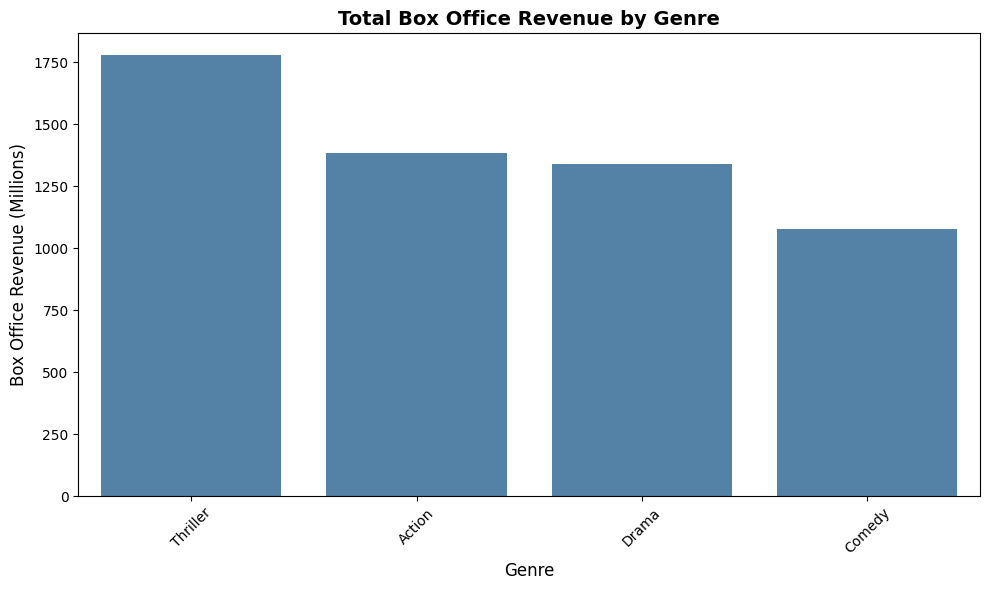

In [5]:
# Calculate total box-office revenue for each genre
genre_box_office = (
    df.groupby("Genre", as_index=False)["Box_Office_Millions"]
      .sum()
      .sort_values("Box_Office_Millions", ascending=False)
)

# Display totals
print("Total Box Office Revenue by Genre (Millions):")
print(genre_box_office)

# Create bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=genre_box_office,
    x="Genre",
    y="Box_Office_Millions",
    color="steelblue"
)

# Chart formatting
plt.title("Total Box Office Revenue by Genre", fontsize=14, fontweight="bold")
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Box Office Revenue (Millions)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

# Display chart
plt.show()


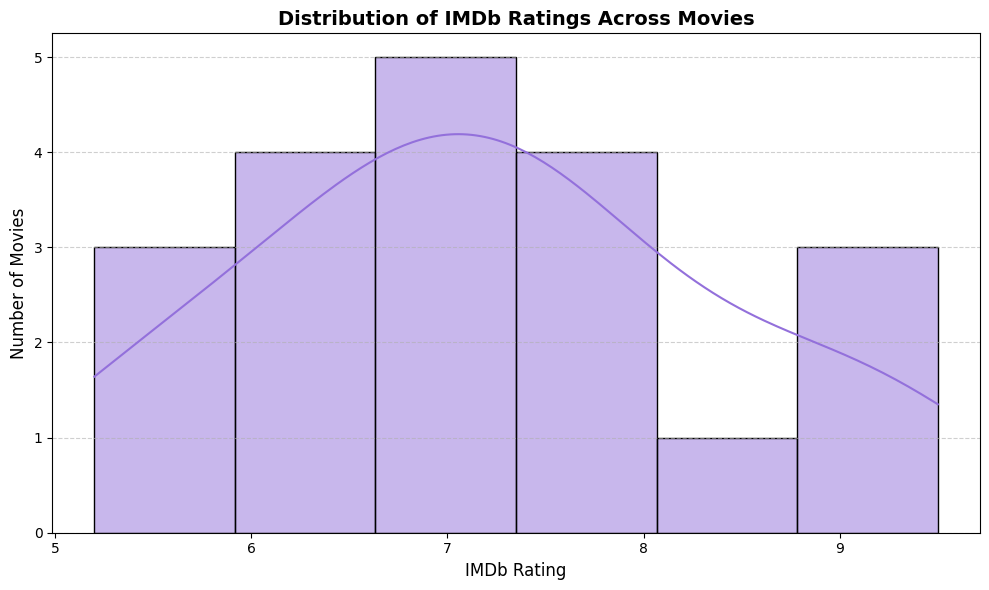

IMDb Rating Summary:
count    20.000000
mean      7.210000
std       1.224272
min       5.200000
25%       6.500000
50%       7.150000
75%       7.850000
max       9.500000
Name: IMDB_Rating, dtype: float64


In [7]:
# Create histogram of IMDb ratings
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="IMDB_Rating",
    bins=6,            # Number of rating intervals
    color="mediumpurple",
    edgecolor="black",
    kde=True           # Optional smooth distribution curve
)

# Chart formatting
plt.title("Distribution of IMDb Ratings Across Movies", fontsize=14, fontweight="bold")
plt.xlabel("IMDb Rating", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Optional numerical summary for interpretation
print("IMDb Rating Summary:")
print(df["IMDB_Rating"].describe())

In [8]:
# Create the Hit column:
# True for movies rated 8.0 or higher; otherwise False
df["Hit"] = df["IMDB_Rating"] >= 8

# Display movie ratings with their hit classification
print(df[["Movie_ID", "Genre", "IMDB_Rating", "Hit"]])

# Optional: count hits and non-hits
hit_summary = df["Hit"].value_counts()
print("\nHit Summary:")
print(hit_summary)

# Optional: calculate the percentage of movies classified as hits
hit_percentage = df["Hit"].mean() * 100
print(f"\nPercentage of critically successful movies: {hit_percentage:.1f}%")


    Movie_ID     Genre  IMDB_Rating    Hit
0       4001  Thriller          6.8  False
1       4002  Thriller          6.1  False
2       4003    Action          7.8  False
3       4004    Comedy          9.5   True
4       4005    Action          6.2  False
5       4006    Action          9.1   True
6       4007     Drama          6.6  False
7       4008    Action          7.3  False
8       4009  Thriller          7.6  False
9       4010  Thriller          6.6  False
10      4011  Thriller          8.6   True
11      4012     Drama          7.6  False
12      4013  Thriller          8.0   True
13      4014  Thriller          9.0   True
14      4015     Drama          5.2  False
15      4016    Comedy          5.3  False
16      4017    Action          7.1  False
17      4018    Comedy          6.9  False
18      4019     Drama          7.2  False
19      4020     Drama          5.7  False

Hit Summary:
Hit
False    15
True      5
Name: count, dtype: int64

Percentage of critically suc

In [9]:
# Create the Hit column if it has not already been created
df["Hit"] = df["IMDB_Rating"] >= 8

# Count total hit movies
total_hits = df["Hit"].sum()

# Calculate hit percentage
hit_percentage = (total_hits / len(df)) * 100

# Display results
print(f"Total number of Hit movies: {total_hits}")
print(f"Hit movie percentage: {hit_percentage:.1f}%")

# Optional: show counts of hits vs. non-hits
print("\nHit vs. Non-Hit Movie Count:")
print(df["Hit"].value_counts())


Total number of Hit movies: 5
Hit movie percentage: 25.0%

Hit vs. Non-Hit Movie Count:
Hit
False    15
True      5
Name: count, dtype: int64
